In [5]:
# Prerequisites
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)

In [6]:
from ponds import PONDS, GAUSS, SIGMOID
import matplotlib.pyplot as plt

## Generating a World Map of Synthetic Data

Using `PONDS` to generate a set of global, synthetic climate data is easy. First, we create an PONDS class object where we specify the number of grid points in latitudinal and longitudinal direction. We also specify how many time steps each time series consists. The PONDS object is initialised with `(lat_size x lon_size)` grid cells, each containing noisy data following a given background trend. <br>

To add one abrupt shift, we simply call the function `PONDS.add_shift()`. This function needs a `shape_method` and a `shift_method` argument which determine the shape of the blob in the grid and the type of abrupt shift in that spatial location. Additionally, the shift method can further be specified by additional `kwargs` arguments in form of a dictionary.

In [7]:
pd = PONDS(
    lat_size=20,
    lon_size=40,
    time_size=200,
    background_noise=0.01,
    background_trend=0.002,
)


pd.add_shift(random_seed=1, shape_method=GAUSS, shift_method=SIGMOID)

shift_dict = {
    "shift_steepness": 0.2,
    "shift_magnitude": 0.5,
}
pd.add_shift(
    random_seed=4,
    shape_method=GAUSS,
    shift_method=SIGMOID,
    kwargs=shift_dict,
)

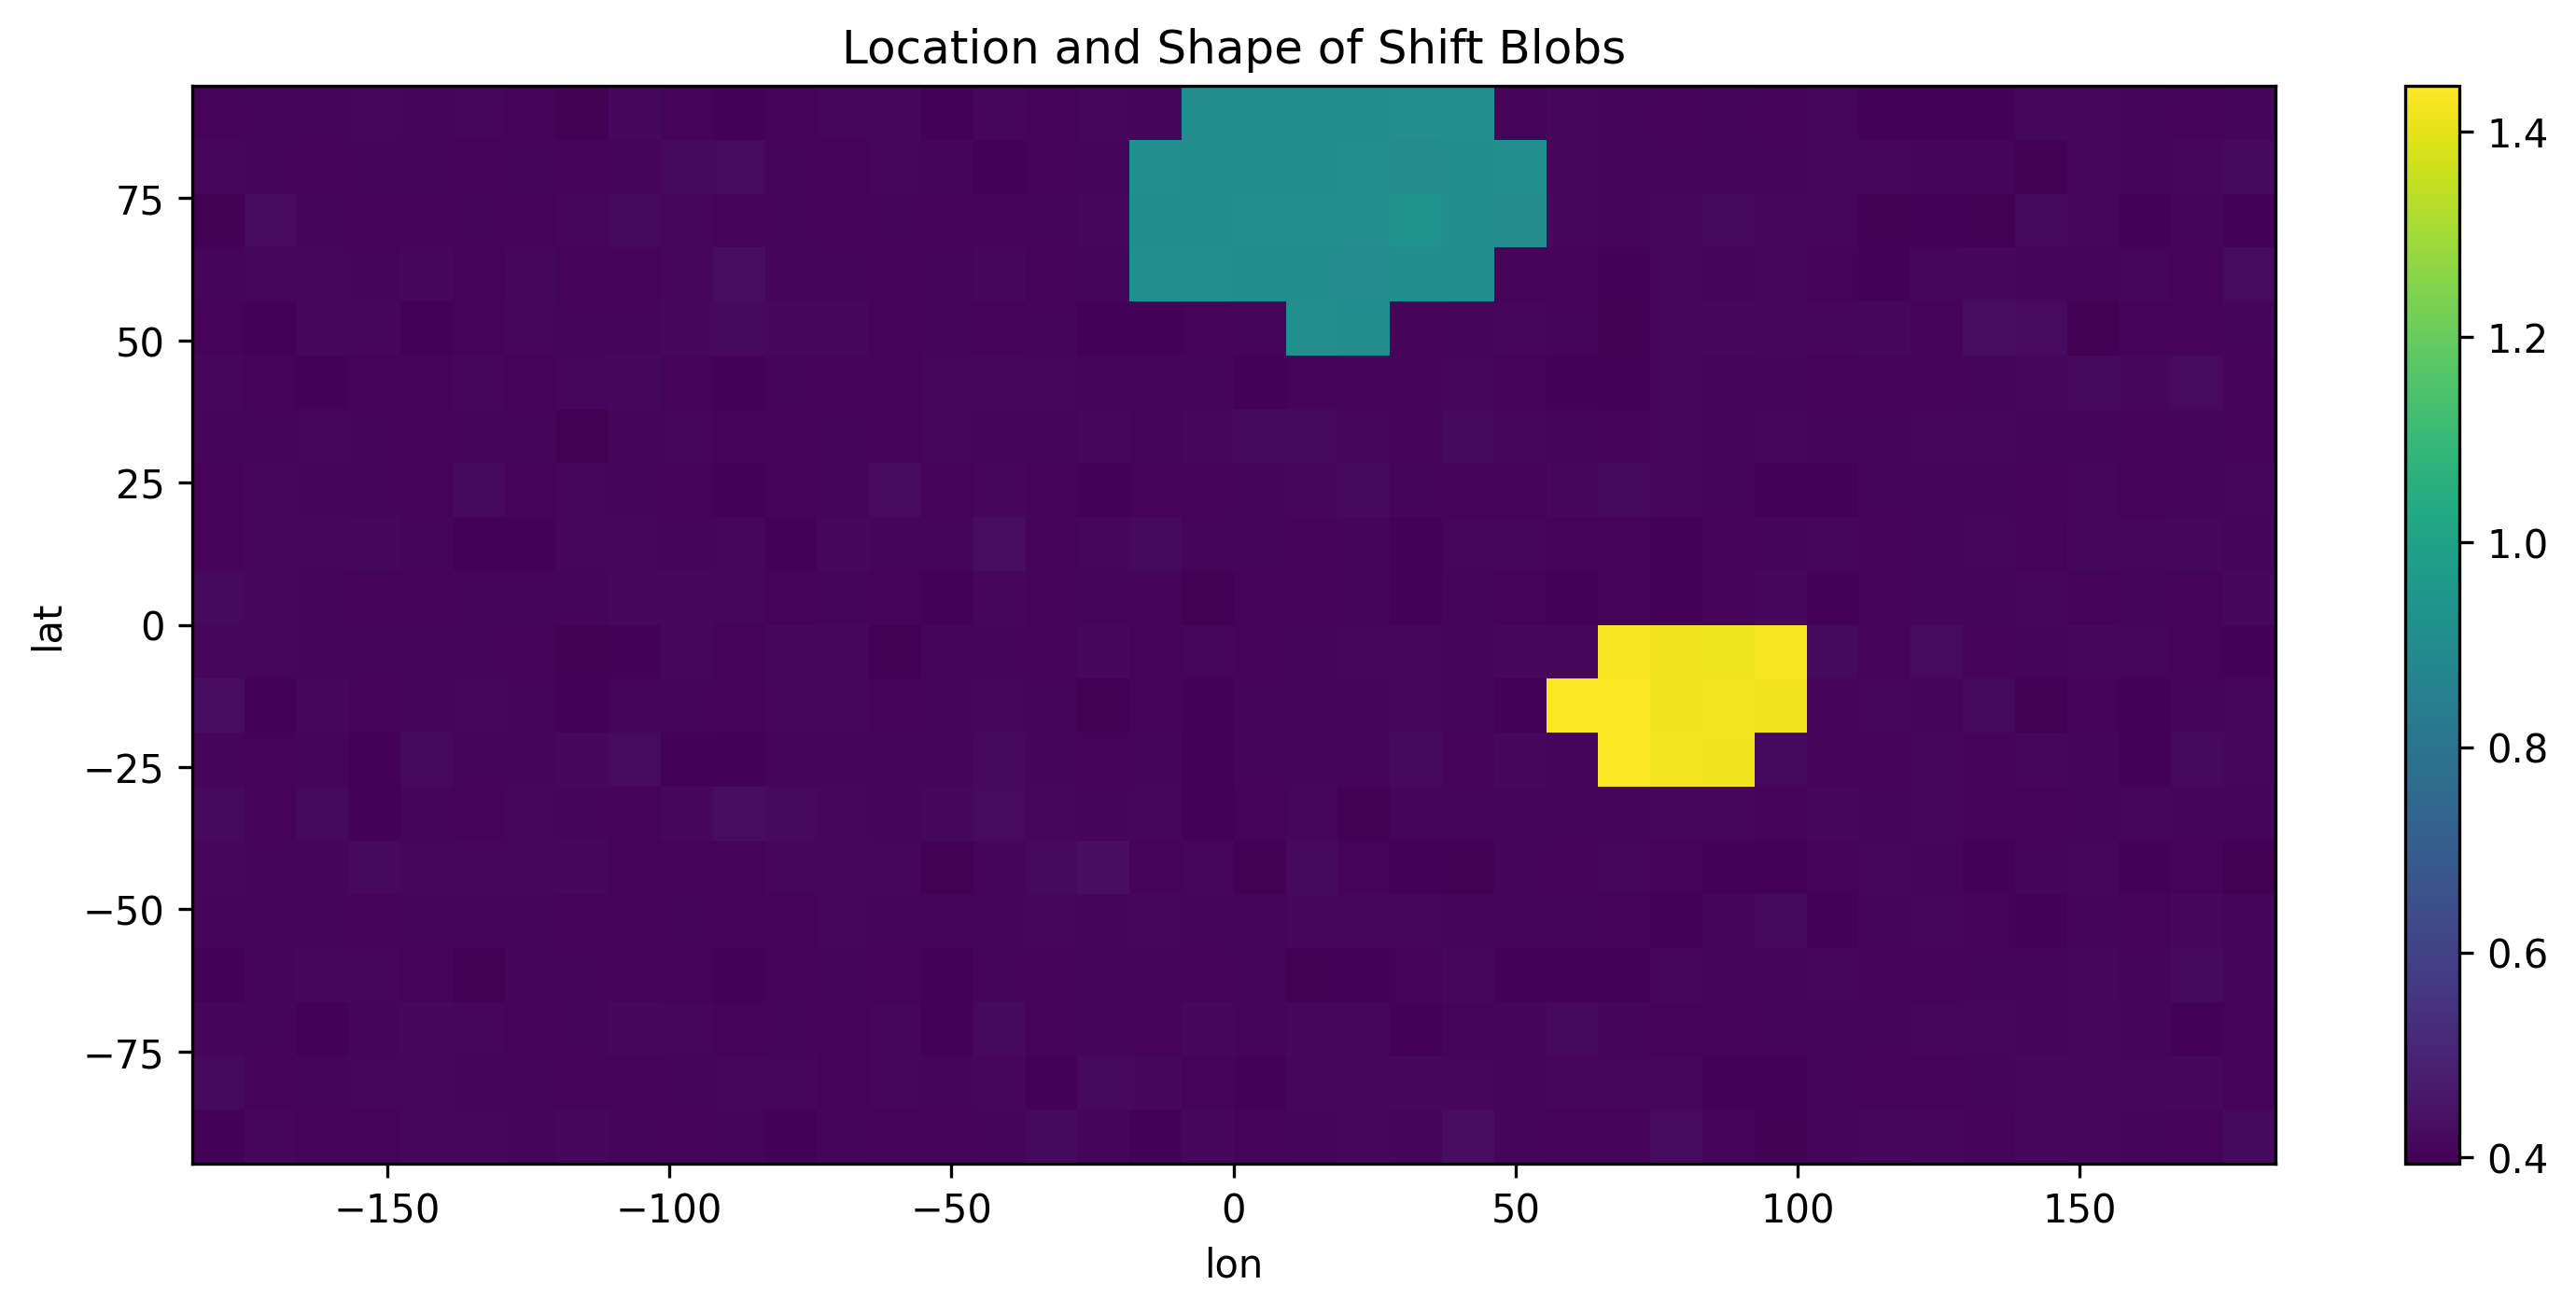

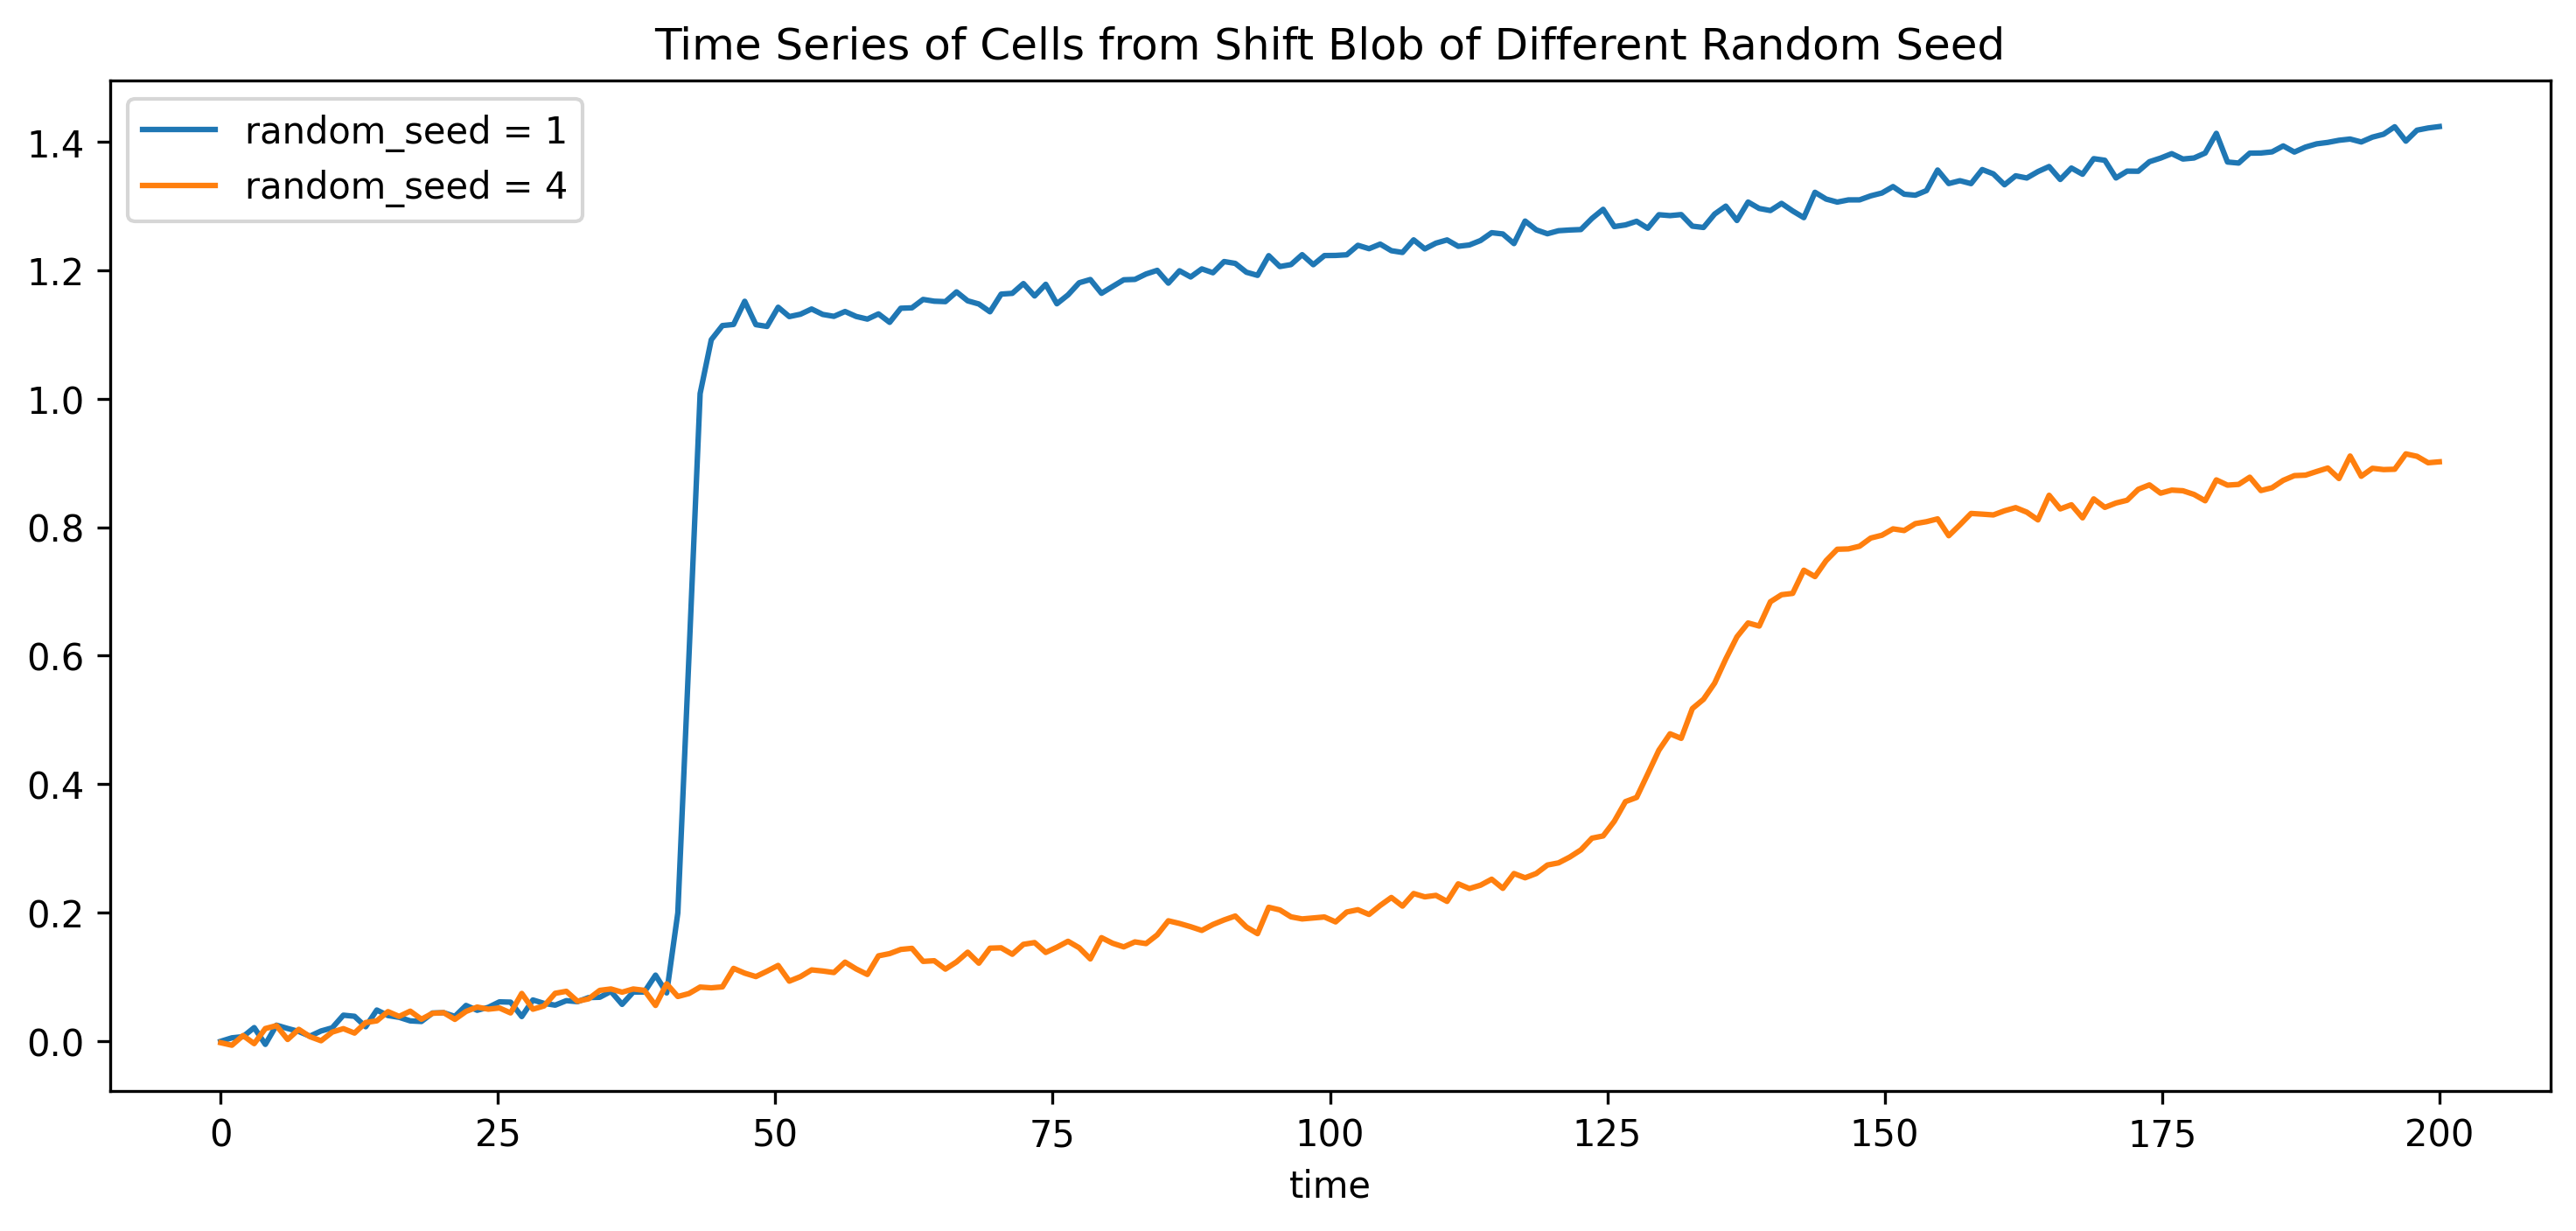

In [8]:
# look at generated time series data
pd.data.max(dim="time").plot()
plt.title("Location and Shape of Shift Blobs")
plt.show()

pd.data.isel(lat=8, lon=28).plot.line(x="time", label="random_seed = 1")
pd.data.isel(lat=17, lon=20).plot.line(x="time", label="random_seed = 4")
plt.legend()
plt.title("Time Series of Cells from Shift Blob of Different Random Seed")
plt.show()

## Using `PONDS` Data with `TOAD`

PONDS is developed in close proximity to TOAD and is therefore highly compatible with this abrupt shift detection package. Here, we want to demonstrate how a use case could look like.


In [9]:
from toad import TOAD
from toad.shifts_detection.methods import ASDETECT
from sklearn.cluster import HDBSCAN
from toad.visualisation.toad_plotter import PlotConfig

KeyboardInterrupt: 

In [ ]:
# from ipywidgets import interact
def plot(random_seed=0, n_shifts=1):
    pd = PONDS(
        lat_size=20,
        lon_size=30,
        time_size=200,
        random_seed=random_seed,
        background_noise=0.05,
    )

    for n in range(n_shifts):
        print(f">> Adding Shift {n + 1}/{n_shifts}...")
        pd.add_shift(shape_method=GAUSS, shift_method=SIGMOID)

    data_ds = pd.data.to_dataset(name="value")
    td = TOAD(data_ds)
    td.compute_shifts("value", ASDETECT())
    td.compute_clusters(
        "value",
        HDBSCAN(min_cluster_size=10),
        shifts_filter_func=lambda x: abs(x) > 0.9,
    )

    plt.rcParams["figure.dpi"] = 300

    plotter = td.plotter(
        PlotConfig(
            map_frame=False,
            grid_labels=False,
        )
    )

    plotter.cluster_overview(
        "value",
        range(10),
        cmap="tab10",
        timeseries_kwargs={},
        map_kwargs={"add_contour": False},
        figsize=(16, 5),
    )

    # Plot true shift locations
    fig, ax = plotter.map(figsize=(16, 4))
    pd.data.max(dim="time").plot(ax=ax, cmap="Blues")
    ax.set_title("True shift locations")

    # plot cluster timeseries
    fig, axs = plt.subplots(2, 1, figsize=(16, 4))
    plotter.cluster_timeseries("value", td.get_cluster_ids("value"), ax=axs[0])

    # plot data timeseries
    td.data.value.toad.to_timeseries().plot.line(
        x="time", add_legend=False, color="k", alpha=0.1, ax=axs[1]
    )
    axs[0].set_title(f"Cluster {td.get_cluster_ids('value')} timeseries")
    axs[1].set_title("All data timeseries")

>> Adding Shift 1/2...
>> Adding Shift 2/2...


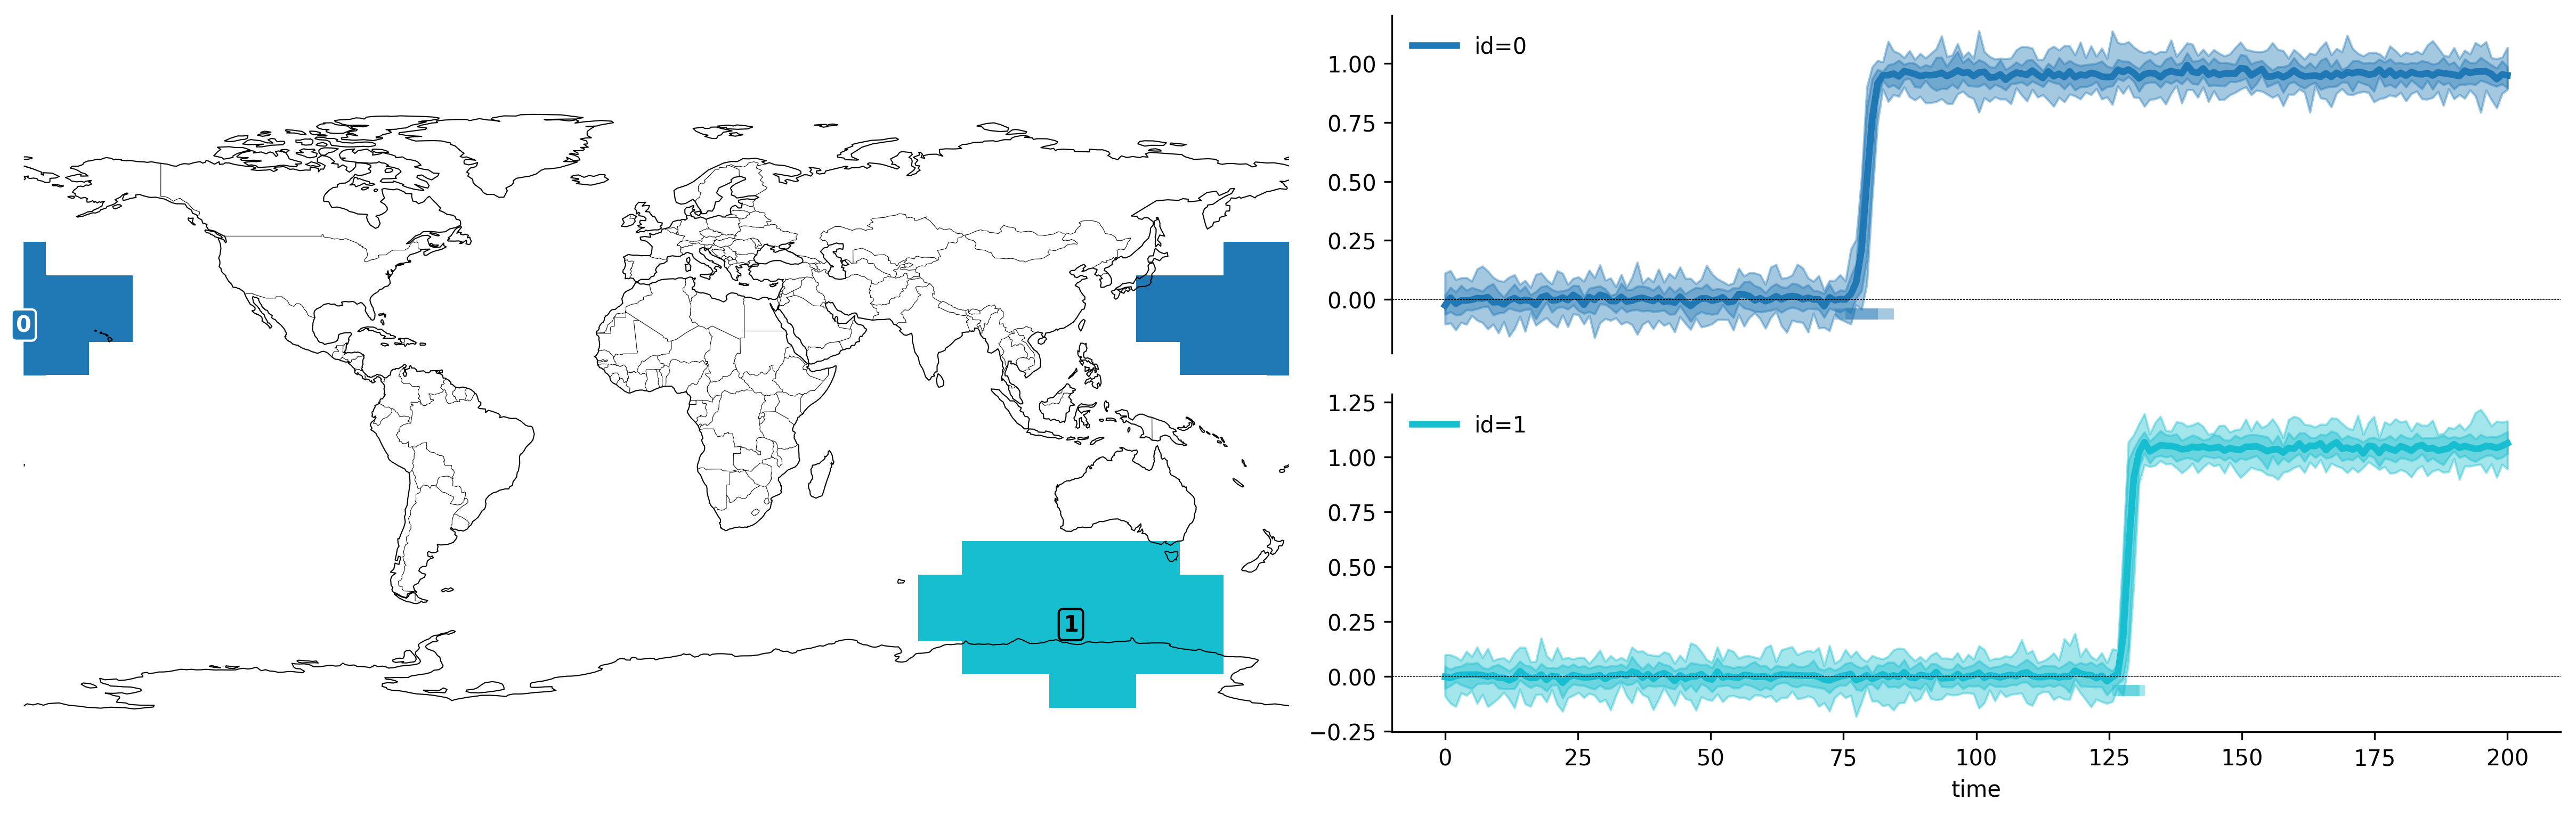

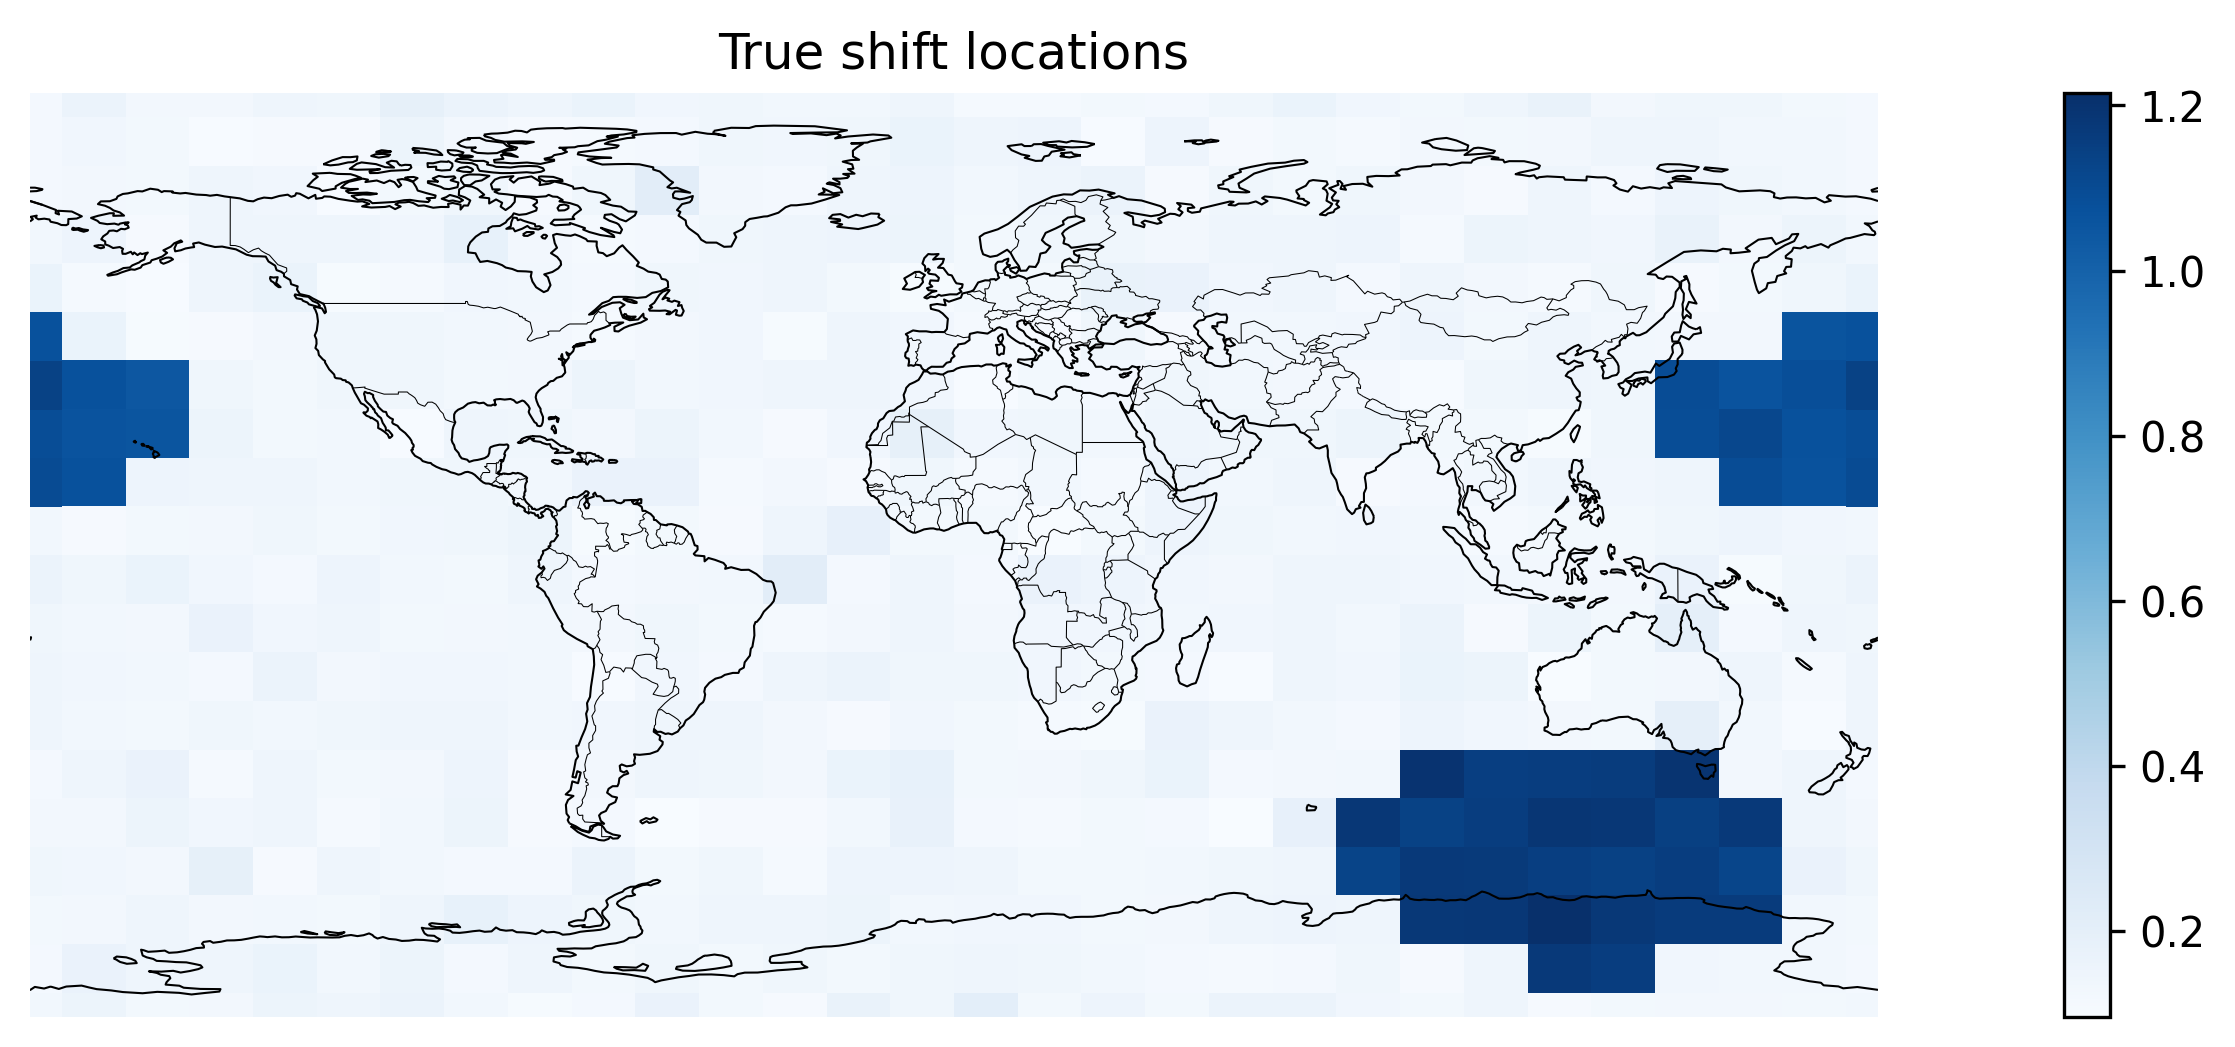

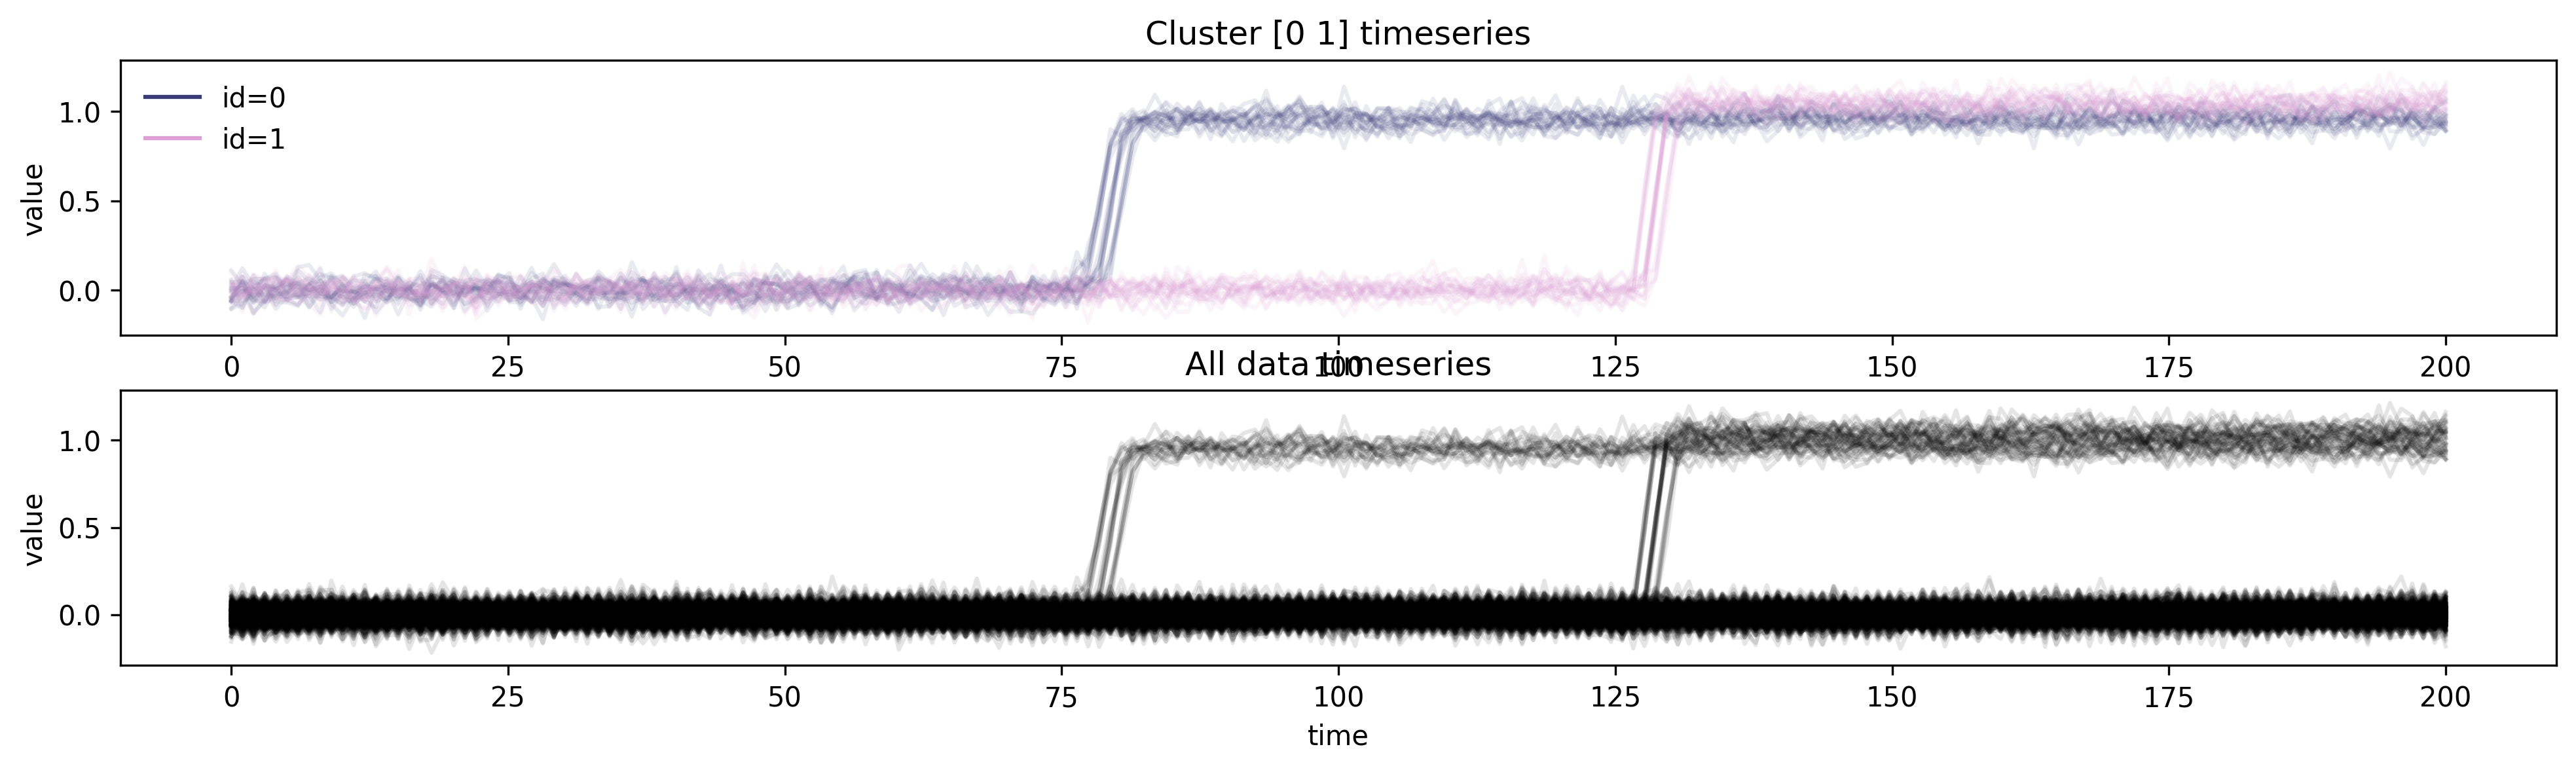

In [ ]:
plot(random_seed=2, n_shifts=2)

## Creating a Single Time Series

Another advantage of `PONDS` is that it can also be used to generate single time series. For that matter, we use the `shape_method = SINGLE`. This method is special compared to other shape methods. When calling it **for the first time** with a given PONDS object that is not of the shape `(lat_size x lon_size) = (1 x 1)`, it **erases all previously generated content** in the time series of the class object and generates a new grid, containing only a single time series. This time series can be modified the same way as before by adding abrupt shifts.

In [ ]:
from ponds import PONDS, SINGLE, SIGMOID
import matplotlib.pyplot as plt

In [ ]:
pd = PONDS(
    time_size=200,
    background_noise=0.01,
    background_trend=0.002,
)

# first time calling SINGLE shape method:
# this will erase all previous time series and rehsape the ponds object grid
# -> will trigger a UserWarning
pd.add_shift(
    random_seed=1,
    shape_method=SINGLE,
    shift_method=SIGMOID,
)

# second time calling SINGLE shape method:
# previous time series (including the shift) is conserved and the new shift is added
shift_dict = {"shift_magnitude": -1}
pd.add_shift(
    random_seed=2,
    shape_method=SINGLE,
    shift_method=SIGMOID,
    kwargs=shift_dict,
)

/home/lukasro/Documents/TIPMIP/ponds/ponds/blobgen.py:110: UserWarning: Shape method SINGLE used on a non-single ponds object.This step erases all time series and starts the ponds object over.
  warnings.warn(


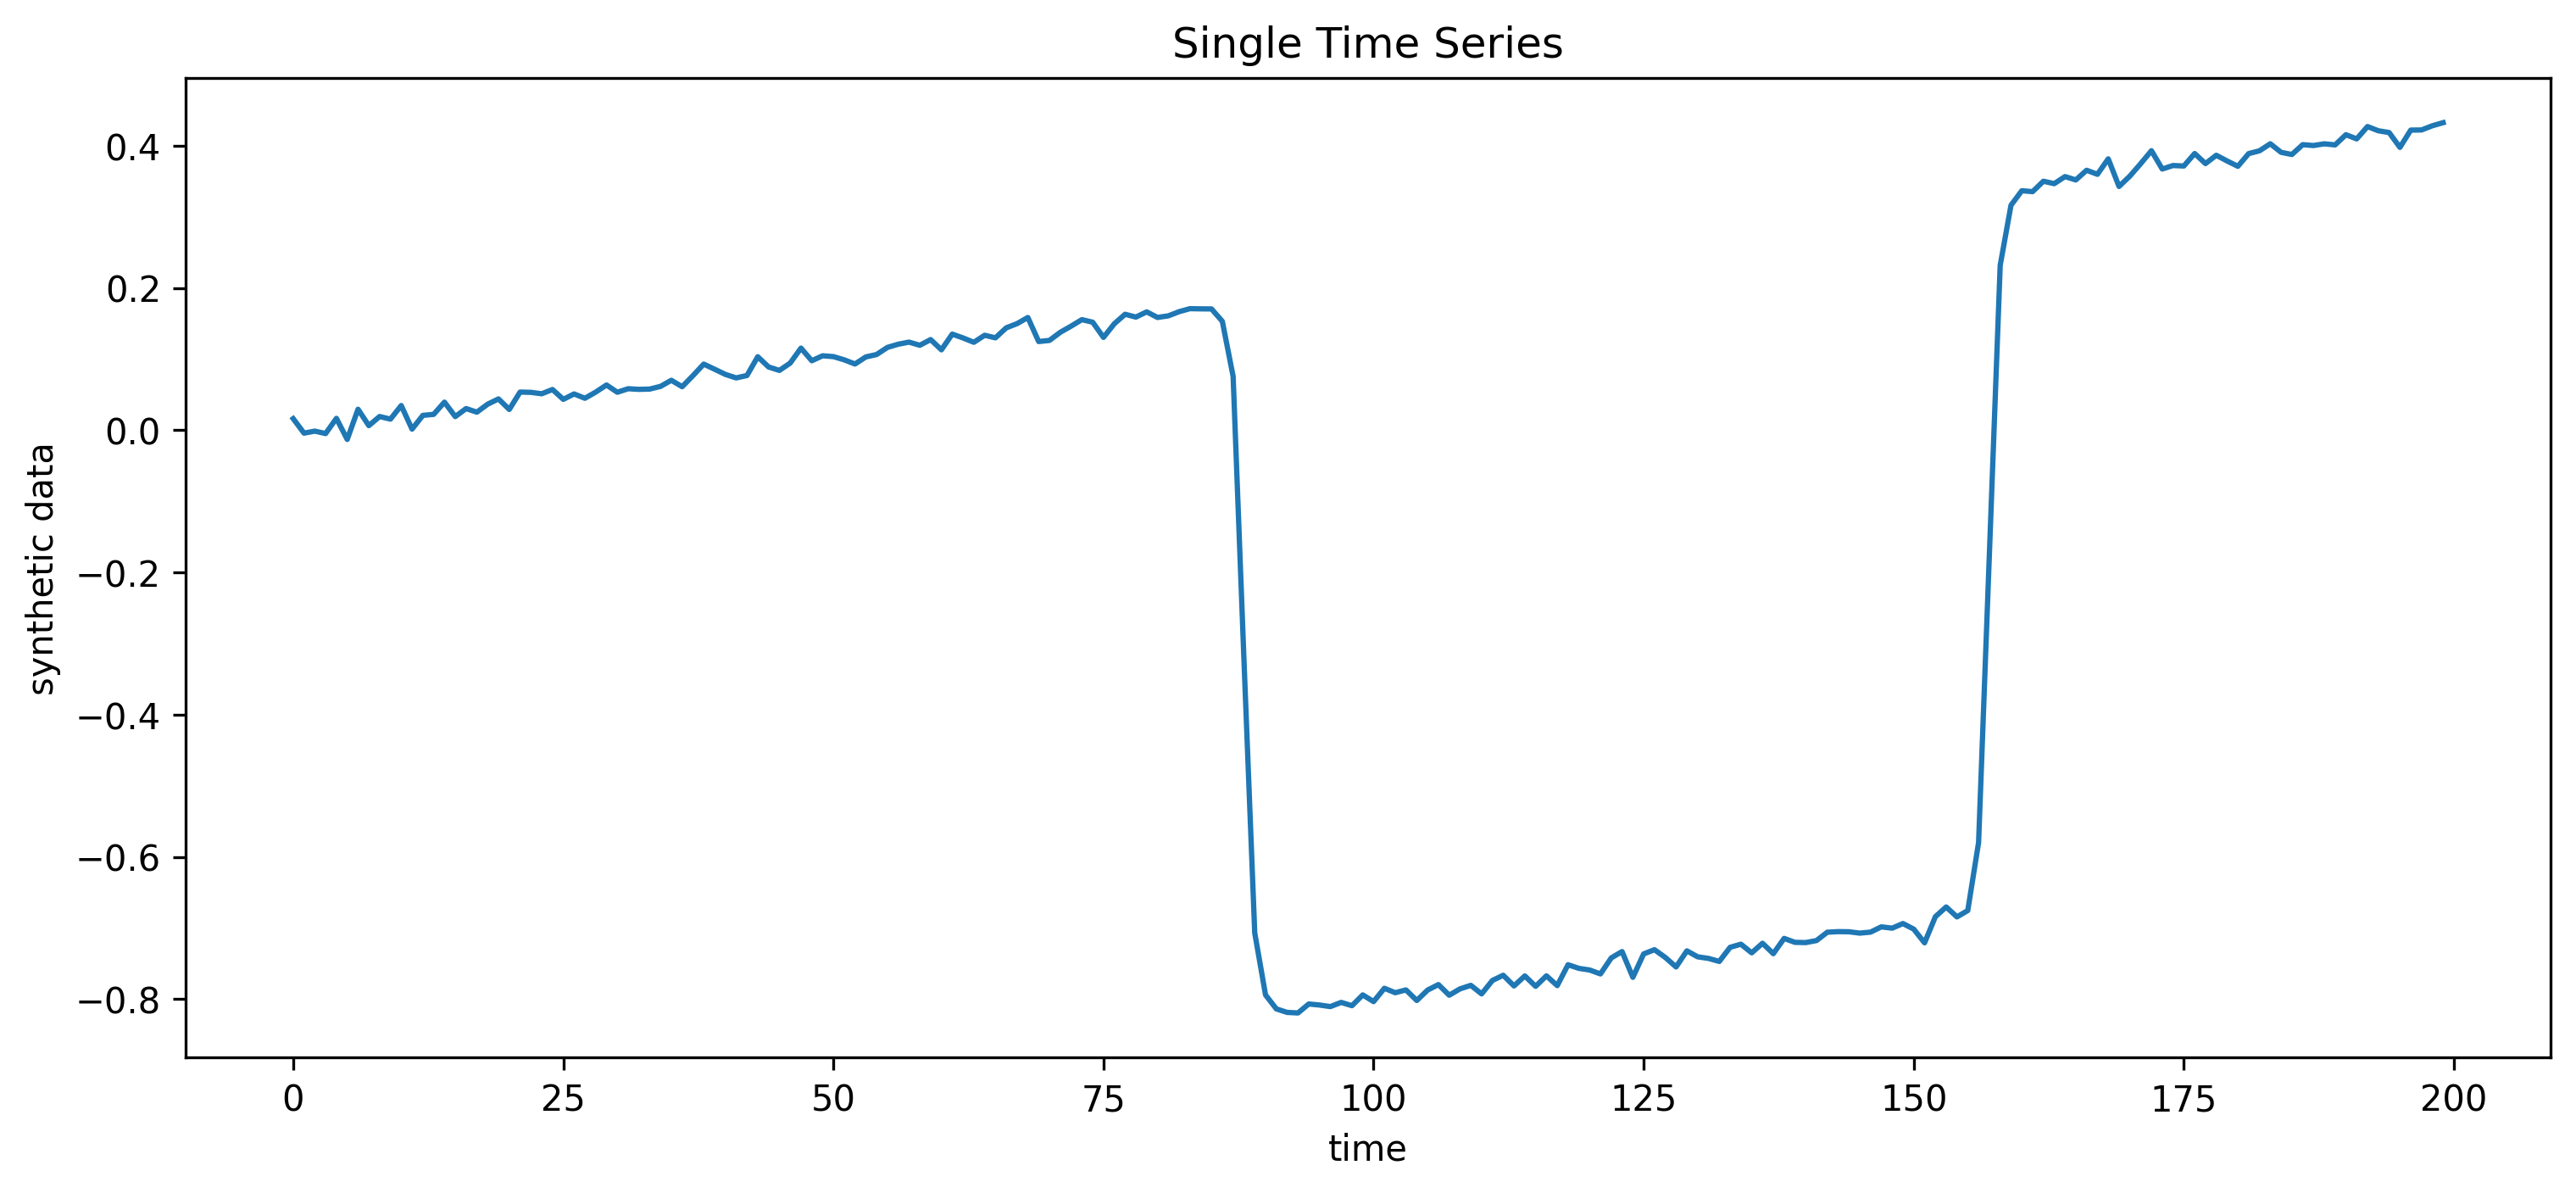

In [ ]:
# get the single time series
ts = pd.get_ts(single=True)

# plot the single time series
plt.plot(ts)

plt.title("Single Time Series")
plt.xlabel("time")
plt.ylabel("synthetic data")
plt.show()

## Sandbox

In [1]:
# Define test configurations
test_configs = [
    {"lat_size": 10, "lon_size": 20, "time_size": 500},
    {"lat_size": 20, "lon_size": 40, "time_size": 500},
    {"lat_size": 50, "lon_size": 100, "time_size": 500},
    {"lat_size": 100, "lon_size": 200, "time_size": 500},
    {"lat_size": 500, "lon_size": 1000, "time_size": 500},
]

# Number of repetitions for averaging
n_repeats = 50

In [2]:
# time approach from main-branch

import time
import numpy as np
from ponds import GAUSS

from ponds.shiftgen_main import SIGMOID as SIGMOID_main
from ponds.core_main import PONDS as PONDS_main

from ponds.shiftgen_new import SIGMOID as SIGMOID_new
from ponds.core_new import PONDS as PONDS_new

# Store results
results_main = []
results_new = []

for config in test_configs:
    times_main = []
    times_new = []
    print(f"\nTesting config: lat={config['lat_size']}, lon={config['lon_size']}, time={config['time_size']}... ", end='')
    
    for i in range(n_repeats):
        # main-branch approach
        pd = PONDS_main(
            lat_size=config["lat_size"],
            lon_size=config["lon_size"],
            time_size=config["time_size"],
            background_noise=0.01,
            background_trend=0.002,
        )
        
        start_time = time.time()
        
        # Call your function under test
        pd.add_shift(random_seed=1, shape_method=GAUSS, shift_method=SIGMOID_main)
        
        elapsed_time = time.time() - start_time
        times_main.append(elapsed_time)

        # new-branch approach
        pd = PONDS_new(
            lat_size=config["lat_size"],
            lon_size=config["lon_size"],
            time_size=config["time_size"],
            background_noise=0.01,
            background_trend=0.002,
        )
        
        start_time = time.time()
        
        # Call your function under test
        pd.add_shift(random_seed=1, shape_method=GAUSS, shift_method=SIGMOID_new)
        
        elapsed_time = time.time() - start_time
        times_new.append(elapsed_time)
    
    mean_time_main = np.mean(times_main)
    std_time_main = np.std(times_main)
    mean_time_new = np.mean(times_new)
    std_time_new = np.std(times_new)
    
    results_main.append({
        "config": config,
        "mean_time": mean_time_main,
        "std_time": std_time_main,
    })
    results_new.append({
        "config": config,
        "mean_time": mean_time_new,
        "std_time": std_time_new,
    })
    print(f"Done!\n=> Main-Approach -\tmean: {mean_time_main:.4f}s, std: {std_time_main:.4f}s")
    print(f"=> New-Approach -\tmean: {mean_time_new:.4f}s, std: {std_time_new:.4f}s")

# Display results
print("\n=== Performance Test Results ===")
for res in results_main:
    cfg = res["config"]
    print(f"lat={cfg['lat_size']:>4}, lon={cfg['lon_size']:>4}, time={cfg['time_size']:>4} "
          f"=> mean: {res['mean_time']:.4f}s, std: {res['std_time']:.4f}s")



Testing config: lat=10, lon=20, time=500... Done!
=> Main-Approach -	mean: 0.0044s, std: 0.0010s
=> New-Approach -	mean: 0.0043s, std: 0.0008s

Testing config: lat=20, lon=40, time=500... Done!
=> Main-Approach -	mean: 0.0047s, std: 0.0007s
=> New-Approach -	mean: 0.0050s, std: 0.0008s

Testing config: lat=50, lon=100, time=500... Done!
=> Main-Approach -	mean: 0.0114s, std: 0.0012s
=> New-Approach -	mean: 0.0133s, std: 0.0013s

Testing config: lat=100, lon=200, time=500... Done!
=> Main-Approach -	mean: 0.0400s, std: 0.0057s
=> New-Approach -	mean: 0.0506s, std: 0.0084s

Testing config: lat=500, lon=1000, time=500... Done!
=> Main-Approach -	mean: 0.9249s, std: 0.0866s
=> New-Approach -	mean: 1.1215s, std: 0.1056s

=== Performance Test Results ===
lat=  10, lon=  20, time= 500 => mean: 0.0044s, std: 0.0010s
lat=  20, lon=  40, time= 500 => mean: 0.0047s, std: 0.0007s
lat=  50, lon= 100, time= 500 => mean: 0.0114s, std: 0.0012s
lat= 100, lon= 200, time= 500 => mean: 0.0400s, std: 0.00

In [4]:
# Compare results_main and results_new row by row
print("\n=== Comparison of Main and New Approaches ===")
print(f"Average over {n_repeats} repetitions for each configuration\n")
for idx, (main, new) in enumerate(zip(results_main, results_new)):
    cfg = main["config"]
    print(f"Config {idx+1}: lat={cfg['lat_size']}, lon={cfg['lon_size']}, time={cfg['time_size']}")
    print(f"  main: mean={main['mean_time']:.6f}s, std={main['std_time']:.6f}s")
    print(f"  new : mean={new['mean_time']:.6f}s, std={new['std_time']:.6f}s")
    print(f"  diff: mean={new['mean_time'] - main['mean_time']:.6f}s, std={new['std_time'] - main['std_time']:.6f}s\n")


=== Comparison of Main and New Approaches ===
Average over 50 repetitions for each configuration

Config 1: lat=10, lon=20, time=500
  main: mean=0.004383s, std=0.000950s
  new : mean=0.004308s, std=0.000827s
  diff: mean=-0.000075s, std=-0.000123s

Config 2: lat=20, lon=40, time=500
  main: mean=0.004708s, std=0.000652s
  new : mean=0.004957s, std=0.000758s
  diff: mean=0.000250s, std=0.000106s

Config 3: lat=50, lon=100, time=500
  main: mean=0.011420s, std=0.001187s
  new : mean=0.013298s, std=0.001259s
  diff: mean=0.001878s, std=0.000073s

Config 4: lat=100, lon=200, time=500
  main: mean=0.039952s, std=0.005685s
  new : mean=0.050593s, std=0.008353s
  diff: mean=0.010642s, std=0.002668s

Config 5: lat=500, lon=1000, time=500
  main: mean=0.924882s, std=0.086609s
  new : mean=1.121549s, std=0.105582s
  diff: mean=0.196666s, std=0.018973s



### Approaches for iterating outside of the shiftgen method:

- shiftgen method returns a generated time series, which is added to original times series in core
- shiftgen receives cell indices and internally accesses the ponds object to write the new time series
- ...

**Testing Tools:**
- computation time
- profiling